# Что измеряет синтетический v2?

Анализ текстов и зафиксированной mixed-модели char_wb46k. Данные, веса и пороги0.5 не менялись, новые fit и поиск гиперпараметров не запускались. Эта тетрадь читает готовые результаты аудита.

Реалистичность — прозрачная экспертная текстовая эвристика, не измерение распространённости на настоящем Авито. Сложность не определяется ошибкой модели. Исходные729строк — **validation**, использованная для выбора конфигураций, не отдельный финальный test. Public208 — другой файл.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'avito_compare').is_dir() and (p/'output').is_dir())
OUT=ROOT/'output/v2-complexity-audit'
stats=json.loads((OUT/'statistics.json').read_text())
proof=json.loads((OUT/'collision_proof.json').read_text())
groups=['realistic','plausible_hard','artificial']
labels=['Реалистичные','Сложные правдоподобные','Искусственные']
def table(headers,rows):
    text='| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'
    display(Markdown(text+'\n'.join('| '+' | '.join(map(str,r))+' |' for r in rows)))
table(['Корпус','Строк','Медиана символов','p95 символов','Максимум'],[[n,stats['datasets'][n]['rows'],*[stats['datasets'][n]['length_chars'][k] for k in ['median','p95','max']]] for n in ['public_dedup','v2_train','v2_test']])
table(['Экспертная группа','Всего v2','Доля v2, %','Test строк','Test F1','P','R','FP','FN'],[[label,stats['datasets']['v2_all']['realism'][g],round(100*stats['datasets']['v2_all']['realism'][g]/stats['datasets']['v2_all']['rows'],2),*[round(stats['evaluation']['v2_test']['realism'][g][k],5) for k in ['rows','micro_f1','precision','recall','fp','fn']]] for g,label in zip(groups,labels)])

| Корпус | Строк | Медиана символов | p95 символов | Максимум |
| --- | --- | --- | --- | --- |
| public_dedup | 4855 | 1467.0 | 4952.0 | 5564.0 |
| v2_train | 8464 | 143.0 | 409.0 | 530.0 |
| v2_test | 3016 | 155.0 | 415.0 | 433.0 |

| Экспертная группа | Всего v2 | Доля v2, % | Test строк | Test F1 | P | R | FP | FN |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Реалистичные | 3327 | 23.83 | 124 | 0.71685 | 0.65789 | 0.7874 | 52 | 27 |
| Сложные правдоподобные | 6217 | 44.53 | 1176 | 0.34332 | 0.69394 | 0.22808 | 187 | 1435 |
| Искусственные | 4416 | 31.63 | 1716 | 0.49402 | 0.6776 | 0.38871 | 452 | 1494 |

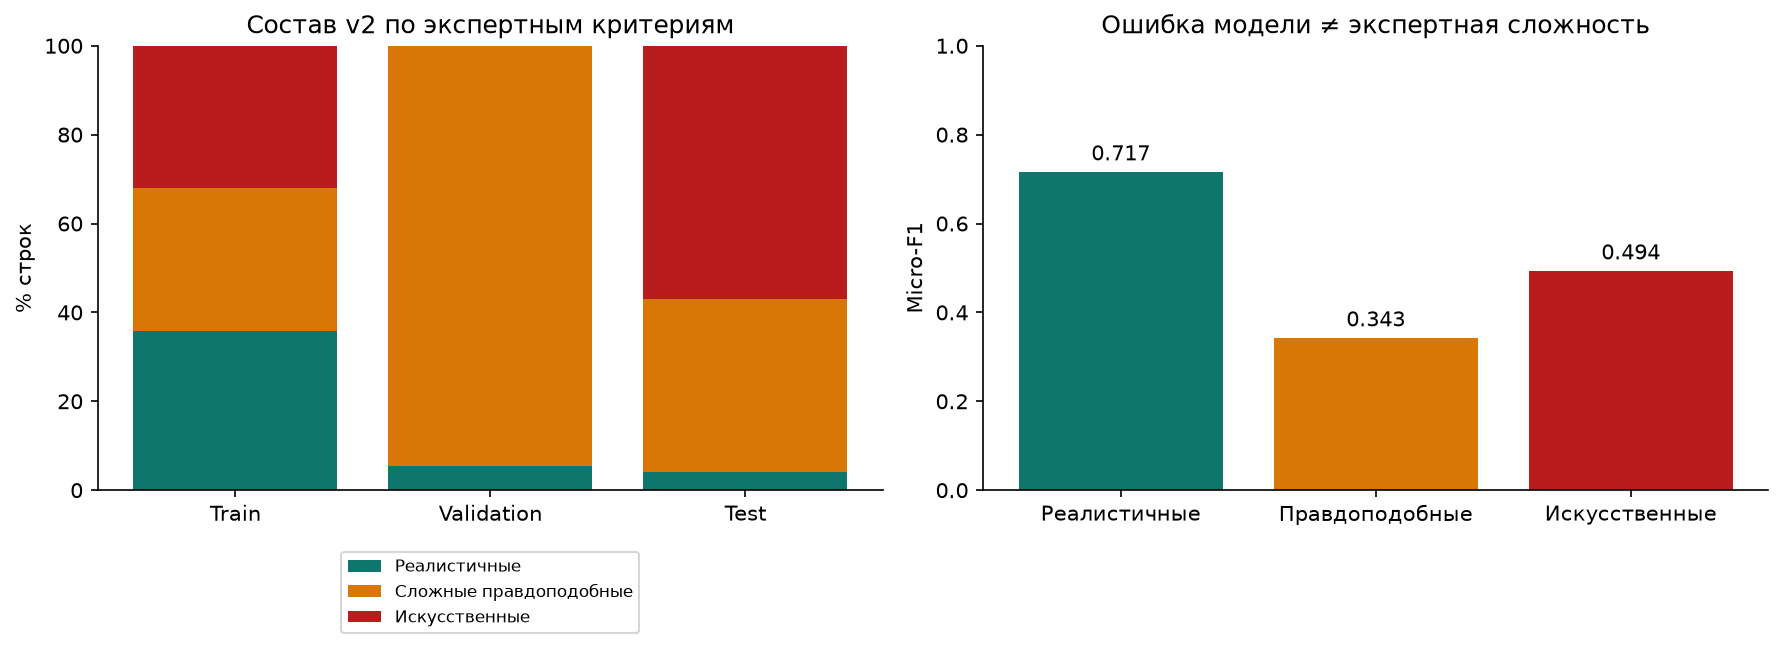

In [2]:
plt.rcParams.update({'font.family':'DejaVu Sans','axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
x=np.arange(3);bottom=np.zeros(3);names=['v2_train','v2_validation','v2_test']
for g,label,color in zip(groups,labels,['#0f766e','#d97706','#b91c1c']):
    values=np.array([100*stats['datasets'][n]['realism'].get(g,0)/stats['datasets'][n]['rows'] for n in names])
    axes[0].bar(x,values,bottom=bottom,label=label,color=color);bottom+=values
axes[0].set(xticks=x,xticklabels=['Train','Validation','Test'],ylabel='% строк',title='Состав v2 по экспертным критериям')
axes[0].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.12))
values=[stats['evaluation']['v2_test']['realism'][g]['micro_f1'] for g in groups]
bars=axes[1].bar(x,values,color=['#0f766e','#d97706','#b91c1c']);axes[1].bar_label(bars,fmt='%.3f',padding=3)
axes[1].set(xticks=x,xticklabels=['Реалистичные','Правдоподобные','Искусственные'],ylim=(0,1),ylabel='Micro-F1',title='Ошибка модели ≠ экспертная сложность')
fig.tight_layout();fig.savefig(OUT/'01_realism_and_quality.png',dpi=150,bbox_inches='tight');plt.close(fig)
display(Image(filename=str(OUT/'01_realism_and_quality.png')))

In [3]:
evaluation=stats['evaluation']['v2_test']
table(['Срез','Строк','F1','FP','FN','Пустых ответов'],[[name,*[round(m[k],5) for k in ['rows','micro_f1','fp','fn','empty_predictions']]] for name,m in evaluation['type'].items()])
overall=evaluation['overall']
print('Пустых ответов:',overall['empty_predictions'],'из',overall['rows'])
print('Пустых ответов при непустом эталоне:',overall['empty_on_positive_rows'])
print('Точных коллизий представления:',proof['conflicting_groups'],'групп /',proof['rows'],'строк')
print('Нижняя граница ошибок полного набора при этом представлении:',proof['minimum_exact_set_errors'])
pair=proof['examples'][-1]
for row in pair['rows']:
    print('\n',row['item_id'],'source=',row['source_mcId'],'gold=',row['gold_102_106'])
    print(row['description']);print('Scores:',row['scores'])
assert pair['sparse_indices_bitwise_equal'] and pair['sparse_values_bitwise_equal'] and pair['scores_bitwise_equal']
print('Разность векторов nnz=',pair['vector_difference_nnz'])

| Срез | Строк | F1 | FP | FN | Пустых ответов |
| --- | --- | --- | --- | --- | --- |
| colloquial-10 | 2 | 0.66667 | 2 | 0 | 0 |
| colloquial-11 | 2 | 0.0 | 0 | 2 | 2 |
| concord_never | 540 | 0.70053 | 157 | 185 | 136 |
| double_report | 540 | 0.83871 | 225 | 0 | 30 |
| four_layers | 540 | 0.61893 | 225 | 222 | 105 |
| list_status | 60 | 0.66667 | 50 | 0 | 0 |
| long_distance | 60 | 0.07407 | 2 | 48 | 56 |
| rumour | 60 | 0.46154 | 30 | 26 | 11 |
| status_confirmation | 576 | 0.0 | 0 | 1224 | 576 |
| status_negated_denial | 576 | 0.0 | 0 | 1224 | 576 |
| unless | 60 | 0.79339 | 0 | 25 | 12 |

Пустых ответов: 1504 из 3016
Пустых ответов при непустом эталоне: 1302
Точных коллизий представления: 231 групп / 642 строк
Нижняя граница ошибок полного набора при этом представлении: 390

 v2-status_confirmation-17-1-0-clean source= 104 gold= [105]
Ответы на вопросы об услугах:
Выполняем ли полный цикл ремонта дома со сдачей готового результата? Да, выполняем.
Выполняем ли механизированную штукатурку стен? Нет, не выполняем.
Выполняем ли облицовку стен плиткой? Нет, не выполняем.
Выполняем ли разводку водоснабжения и канализации? Нет, не выполняем.
Выполняем ли установку розеток и выключателей? Да, выполняем.
Выполняем ли покраску стен и потолков? Нет, не выполняем.
Scores: [0.1172845011767258, 0.0927459259808262, 0.09034134701021673, 0.1002939090018495, 0.05885096663805217]

 v2-status_confirmation-12-1-0-clean source= 104 gold= [103]
Ответы на вопросы об услугах:
Выполняем ли полный цикл ремонта дома со сдачей готового результата? Нет, не выполняем.
Выполняем ли механизированную шт

## Что подтверждено

- V2 значительно короче и лексически более шаблонен, но требует связывать статус предложения с конкретной услугой. Это другая сложность, чем длина исходных объявлений.
- Наиболее искусственная группа не самая провальная. Два шестипозиционных списка дают1152пустых ответа и2448пропусков (82.8%всехFN); именно списки — главный провальный срез.
- Для642строк найдены одинаковые TF-IDF-векторы при одинаковомsource и разныхgold. Порогами эти конкретные пары не разделить. Это доказывает ограничение текущего представления на этих случаях, а не объясняет все ошибки модели.
- Формальный метаязык не равен неверной разметке. В просмотренных семействах и challenge перевёрнутых меток не подтверждено, но есть прагматическая неоднозначность метаопровержений.
- Чистые контрастные пары важнее отдельно высокогоF1шаблона: неизменная вторая услуга может дать высокийF1без различения первой.

## Полный отчёт

`report.md` — сравнения и ответы на шесть вопросов. `examples_full.md` —80полных текстов с объяснениями. `semantic_review.md` — ручная проверка сложных формулировок. `collision_proof.json` — побитная проверка коллизий. В statistics.json сохранены исходныеSHA-256 и проверка их неизменности.

Доли реалистичности зависят от объявленных экспертных критериев. Это не частоты конструкций реального Авито и не причинная оценка вклада искусственности в падениеF1.